# Texas State Government Salary Analysis & Prediction

### Problem Statement
The goal is to analyze the salary data of Texas government employees and create a predictive model for salary. This includes:
- Outlier detection
- Wage disparity analysis
- Time-based trends
- Predictive modeling
- Model comparison and final recommendation

### Importing Libraries

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

### Load Dataset

In [7]:
df = pd.read_csv('salary.csv')
df.head()

,AGENCY,AGENCY NAME,LAST NAME,FIRST NAME,MI,CLASS CODE,CLASS TITLE,ETHNICITY,GENDER,STATUS,...,HRLY RATE,HRS PER WK,MONTHLY,ANNUAL,STATE NUMBER,duplicated,multiple_full_time_jobs,combined_multiple_jobs,summed_annual_salary,hide_from_search
0,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",RUCKER,MORTON,V,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,...,75.96150,29.0,9545.82,114549.84,127717,True,NaN,NaN,131407.08,NaN
1,212,OFFICE OF COURT ADMINISTRATION ...,RUCKER,MORTON,V,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,...,81.04454,4.0,1404.77,16857.24,127717,True,NaN,NaN,NaN,True
2,241,"COMPTROLLER OF PUBLIC ACCOUNTS, JUDICIARY SECT...",SPECIA JR,JOHN,J,JD25,"JUDGE, RETIRED ...",WHITE,MALE,URP - UNCLASSIFIED REGULAR PART-TIME,...,75.96150,29.0,9545.82,114549.84,59115,True,NaN,NaN,131407.08,NaN
3,212,OFFICE OF COURT ADMINISTRATION ...,SPECIA JR,JOHN,J,3524,GENERAL COUNSEL IV ...,WHITE,MALE,CTP - CLASSIFIED TEMPORARY PART-TIME,...,81.04453,4.0,1404.77,16857.24,59115,True,NaN,NaN,NaN,True
4,696,TEXAS DEPARTMENT OF CRIMINAL JUSTICE ...,ONTIVEROS,ESTHER,,4504,CORREC OFFICER IV ...,HISPANIC,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,0.00000,40.0,3284.27,39411.24,165030,True,1.0,NaN,NaN,NaN


### Basic Dataset Information

In [10]:
df.shape

(149481, 21)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149481 entries, 0 to 149480
Data columns (total 21 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   AGENCY                   149481 non-null  int64  
 1   AGENCY NAME              149481 non-null  object 
 2   LAST NAME                149481 non-null  object 
 3   FIRST NAME               149481 non-null  object 
 4   MI                       149481 non-null  object 
 5   CLASS CODE               149481 non-null  object 
 6   CLASS TITLE              149481 non-null  object 
 7   ETHNICITY                149481 non-null  object 
 8   GENDER                   149481 non-null  object 
 9   STATUS                   149481 non-null  object 
 10  EMPLOY DATE              149481 non-null  object 
 11  HRLY RATE                149481 non-null  float64
 12  HRS PER WK               149481 non-null  float64
 13  MONTHLY                  149481 non-null  float64
 14  ANNU

In [14]:
df.describe(include='all')

,AGENCY,AGENCY NAME,LAST NAME,FIRST NAME,MI,CLASS CODE,CLASS TITLE,ETHNICITY,GENDER,STATUS,...,HRLY RATE,HRS PER WK,MONTHLY,ANNUAL,STATE NUMBER,duplicated,multiple_full_time_jobs,combined_multiple_jobs,summed_annual_salary,hide_from_search
count,149481.000000,149481,149481,149481,149481,149481,149481,149481,149481,149481,...,149481.000000,149481.000000,149481.000000,149481.000000,1.494810e+05,143,14.0,97,16.000000,16
unique,NaN,113,38675,23559,27,1481,1422,6,2,11,...,NaN,NaN,NaN,NaN,NaN,1,NaN,1,NaN,1
top,NaN,HEALTH AND HUMAN SERVICES COMMISSION ...,SMITH,MICHAEL,,4504,CORREC OFFICER IV ...,WHITE,FEMALE,CRF - CLASSIFIED REGULAR FULL-TIME,...,NaN,NaN,NaN,NaN,NaN,True,NaN,True,NaN,True
freq,NaN,36667,1243,1843,38408,9267,9267,67142,85328,142502,...,NaN,NaN,NaN,NaN,NaN,143,NaN,97,NaN,16
mean,545.736288,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.346488,39.714918,4226.184248,50714.210973,5.651930e+05,NaN,1.0,NaN,74303.955000,NaN
std,139.057691,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.211485,2.323855,2093.111691,25117.340292,4.786212e+05,NaN,0.0,NaN,51925.944282,NaN
min,101.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,1.000000,50.000000,600.000000,1.000000e+00,NaN,1.0,NaN,18000.000000,NaN
25%,529.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,40.000000,3019.840000,36238.080000,1.133340e+05,NaN,1.0,NaN,32962.500000,NaN
50%,530.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,40.000000,3720.170000,44642.040000,3.463730e+05,NaN,1.0,NaN,48063.300000,NaN
75%,696.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000,40.000000,4865.810000,58389.720000,1.100500e+06,NaN,1.0,NaN,123751.770000,NaN


In [16]:
df.columns

Index(['AGENCY', 'AGENCY NAME', 'LAST NAME', 'FIRST NAME', 'MI', 'CLASS CODE',
       'CLASS TITLE', 'ETHNICITY', 'GENDER', 'STATUS', 'EMPLOY DATE',
       'HRLY RATE', 'HRS PER WK', 'MONTHLY', 'ANNUAL', 'STATE NUMBER',
       'duplicated', 'multiple_full_time_jobs', 'combined_multiple_jobs',
       'summed_annual_salary', 'hide_from_search'],
      dtype='object')

### Checking for Missing Values

In [19]:
df.isnull().sum()

AGENCY                          0
AGENCY NAME                     0
LAST NAME                       0
FIRST NAME                      0
MI                              0
CLASS CODE                      0
CLASS TITLE                     0
ETHNICITY                       0
GENDER                          0
STATUS                          0
EMPLOY DATE                     0
HRLY RATE                       0
HRS PER WK                      0
MONTHLY                         0
ANNUAL                          0
STATE NUMBER                    0
duplicated                 149338
multiple_full_time_jobs    149467
combined_multiple_jobs     149384
summed_annual_salary       149465
hide_from_search           149465
dtype: int64

### Data Cleaning & Formatting

In [22]:
# Drop rows with missing salary
salary_columns = ['MONTHLY', 'ANNUAL']
df = df.dropna(subset=salary_columns)

# Convert Employ Date to datetime
if 'Employ Date' in df.columns:
    df['Employ Date'] = pd.to_datetime(df['Employ Date'], errors='coerce')

### Unique Values and Data Types

In [25]:
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

AGENCY: 113 unique values
AGENCY NAME: 113 unique values
LAST NAME: 38675 unique values
FIRST NAME: 23559 unique values
MI: 27 unique values
CLASS CODE: 1481 unique values
CLASS TITLE: 1422 unique values
ETHNICITY: 6 unique values
GENDER: 2 unique values
STATUS: 11 unique values
EMPLOY DATE: 6295 unique values
HRLY RATE: 206 unique values
HRS PER WK: 58 unique values
MONTHLY: 40552 unique values
ANNUAL: 40554 unique values
STATE NUMBER: 149465 unique values
duplicated: 1 unique values
multiple_full_time_jobs: 1 unique values
combined_multiple_jobs: 1 unique values
summed_annual_salary: 15 unique values
hide_from_search: 1 unique values


## Exploratory Data Analysis (EDA)

### Distribution of Annual Salary

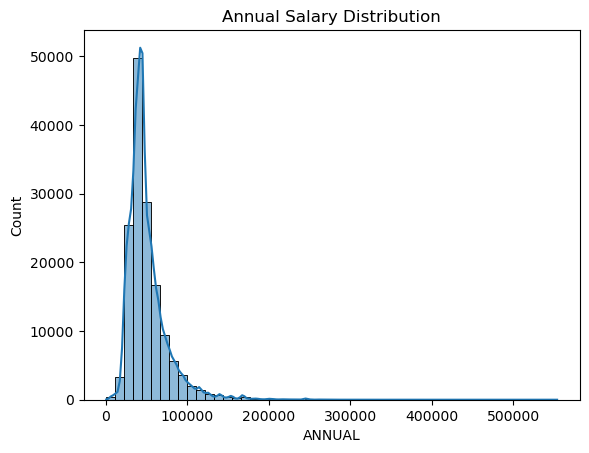

In [29]:
sns.histplot(df['ANNUAL'], bins=50, kde=True)
plt.title('Annual Salary Distribution')
plt.show()

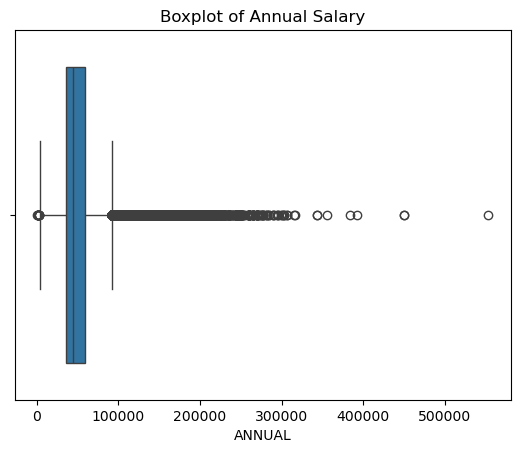

In [31]:
sns.boxplot(x=df['ANNUAL'])
plt.title('Boxplot of Annual Salary')
plt.show()

### Outlier Detection (IQR Method)

In [34]:
q1 = df['ANNUAL'].quantile(0.25)
q3 = df['ANNUAL'].quantile(0.75)
iqr = q3 - q1
outliers = df[(df['ANNUAL'] < q1 - 1.5 * iqr) | (df['ANNUAL'] > q3 + 1.5 * iqr)]
print(f"Outliers detected: {len(outliers)}")
outliers[['FIRST NAME', 'LAST NAME', 'ANNUAL']].head()

Outliers detected: 9031


,FIRST NAME,LAST NAME,ANNUAL
0,MORTON,RUCKER,114549.84
2,JOHN,SPECIA JR,114549.84
5,SHAUNA,ROGERS,154788.00
7,DARREL,SPINKS,120000.00
36,ANNA,BARNETT,96000.00


### Gender and Ethnicity Pay Gap

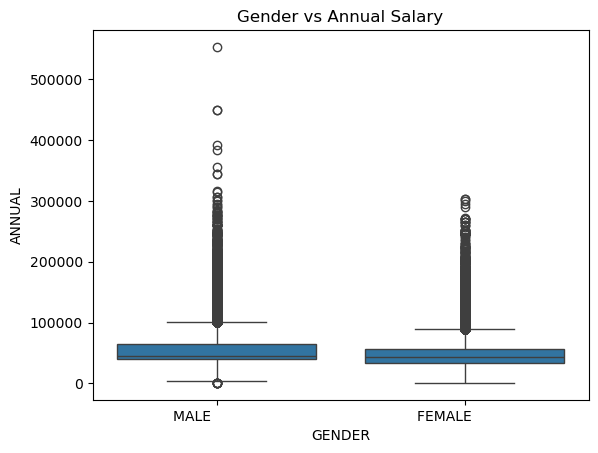

In [37]:
sns.boxplot(x='GENDER', y='ANNUAL', data=df)
plt.title('Gender vs Annual Salary')
plt.show()

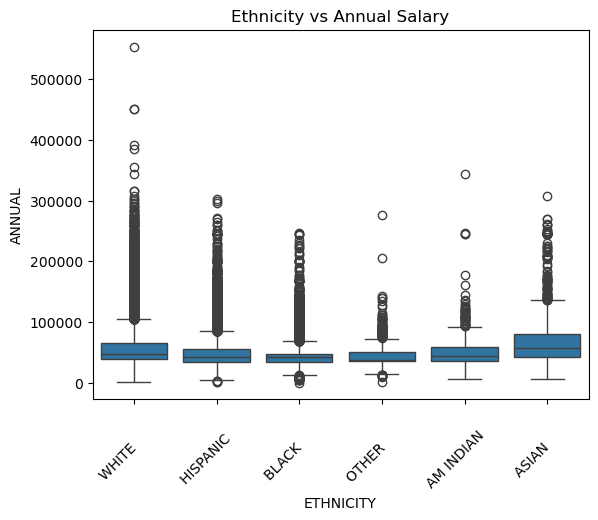

In [39]:
sns.boxplot(x='ETHNICITY', y='ANNUAL', data=df)
plt.title('Ethnicity vs Annual Salary')
plt.xticks(rotation=45)
plt.show()

### Roles with Highest and Lowest Salaries

In [42]:
df.groupby('CLASS TITLE')['ANNUAL'].mean().sort_values(ascending=False).head(10)

CLASS TITLE
CHIEF SCIENTIFIC OFFICER                              553500.000000
DIRECTOR OF INVESTMENTS                               450000.000000
PSF CHIEF INVESTMENT OFFICER                          384375.000000
SENIOR MANAGING DIRECTOR                              319000.000000
EXECUTIVE DIRECTOR FOR ERS                            316116.960000
MANAGING DIRECTOR                                     310999.980000
CHIEF INVESTMENT OFFICER                              300572.000000
CHIEF COMPLIANCE OFFICER                              295800.000000
EX DIRECTOR TDCJ                                      275500.920000
DEPUTY DIRECTOR IV                                    275000.005714
Name: ANNUAL, dtype: float64

In [44]:
df.groupby('CLASS TITLE')['ANNUAL'].mean().sort_values().head(10)

CLASS TITLE
ELECTED OFFICIAL                                       7200.000000
MED TECHNOLOGIST TRAINEE                               7200.000000
COMMISS, SABINE RIVER COMPACT                          8699.160000
COMMISS, CANADIAN RIVER COMPAC                        11036.160000
RESIDENT SPECIALIST I                                 15229.960000
MACHINIST I                                           15594.000000
HOURLY/SUBSTITUTES                                    15781.783256
COMMISSION MEMBERS                                    16311.720000
SUBSTITUTE WORKERS                                    16463.647229
LIBRARY ASST I                                        17762.760000
Name: ANNUAL, dtype: float64

### Average Salary Over Time

In [47]:
if 'Employ Date' in df.columns:
    df['Year'] = df['Employ Date'].dt.year
    salary_by_year = df.groupby('Year')['Annual'].mean().dropna()
    salary_by_year.plot(marker='o', title='Average Salary Over Years')
    plt.ylabel('Annual Salary')
    plt.show()

## Predictive Modeling

In [50]:
# Prepare data for modeling
encoded = pd.get_dummies(df[['AGENCY', 'CLASS TITLE', 'GENDER', 'ETHNICITY']], drop_first=True)
encoded['ANNUAL'] = df['ANNUAL']
X = encoded.drop('ANNUAL', axis=1)
y = encoded['ANNUAL']

In [52]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Linear Regression

In [55]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
from sklearn.metrics import r2_score, mean_squared_error
print('R2:', r2_score(y_test, y_pred_lr))
print('MSE:', mean_squared_error(y_test, y_pred_lr))

R2: -391174306853294.06
MSE: 2.5125194247080572e+23


### Random Forest Regressor

In [58]:
from sklearn.ensemble import RandomForestRegressor

# Optimized Random Forest with fewer trees and limited depth
rf = RandomForestRegressor(
    n_estimators=50,      # fewer trees
    max_depth=10,         # shallower trees
    random_state=42,      # reproducible results
    n_jobs=-1             # use all CPU cores
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

from sklearn.metrics import r2_score, mean_squared_error
print("R² Score:", r2_score(y_test, y_pred_rf))
print("MSE:", mean_squared_error(y_test, y_pred_rf))


R² Score: 0.39238533142795795
MSE: 390271965.91859806


### XGBoost Regressor

In [75]:
from xgboost import XGBRegressor

In [76]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error

# 2. Initialize the model
xgb = XGBRegressor()

# 3. Fit the model to training data
xgb.fit(X_train, y_train)

# 4. Make predictions on test data
y_pred_xgb = xgb.predict(X_test)

# 5. Evaluate the model
print('R² Score:', r2_score(y_test, y_pred_xgb))
print('Mean Squared Error:', mean_squared_error(y_test, y_pred_xgb))

R² Score: 0.7814936083999834
Mean Squared Error: 140347038.0593793


In [74]:
from xgboost import XGBRegressor
xgb = XGBRegressor()
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
print('R2:', r2_score(y_test, y_pred_xgb))
print('MSE:', mean_squared_error(y_test, y_pred_xgb))

R2: 0.7814936083999834
MSE: 140347038.0593793


### Model Comparison

In [81]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost'],
    'R2 Score': [r2_score(y_test, y_pred_lr), r2_score(y_test, y_pred_rf), r2_score(y_test, y_pred_xgb)],
    'MSE': [mean_squared_error(y_test, y_pred_lr), mean_squared_error(y_test, y_pred_rf), mean_squared_error(y_test, y_pred_xgb)]
})
comparison

,Model,R2 Score,MSE
0,Linear Regression,-3.911743e+14,2.512519e+23
1,Random Forest,3.923853e-01,3.902720e+08
2,XGBoost,7.814936e-01,1.403470e+08


### Check for Duplicates

In [84]:
df.duplicated().sum()

0

### Handle Missing Values (If Any)

In [87]:
# Fill missing values with mode or median where applicable
for col in df.columns:
    if df[col].dtype == 'object':
        df[col].fillna(df[col].mode()[0], inplace=True)
    else:
        df[col].fillna(df[col].median(), inplace=True)

df.isnull().sum().sort_values(ascending=False).head()

AGENCY                     0
HRLY RATE                  0
summed_annual_salary       0
combined_multiple_jobs     0
multiple_full_time_jobs    0
dtype: int64

### Frequency of Key Categorical Columns

In [94]:
for col in ['AGENCY', 'CLASS TITLE', 'GENDER', 'ETHNICITY']:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts().head(10))


Value counts for AGENCY:
AGENCY
529    36667
696    35926
601    13099
530    12588
405    10097
320     4653
302     4141
537     3129
802     3060
304     2748
Name: count, dtype: int64

Value counts for CLASS TITLE:
CLASS TITLE
CORREC  OFFICER IV                                    9267
CORREC  OFFICER V                                     7895
CORREC OFFCR III                                      4718
TEXAS WORKS ADVISOR II                                3646
DIRECT SUPPORT PROFESSIONAL I                         3307
TROOPER                                               2251
CHILD PROTECTIVE SVCS SPEC IV                         1854
CHILD PROTECTIVE SVCS SPEC I                          1773
ADMINISTRATIVE ASST III                               1771
SGT OF CORREC OFFCRS                                  1743
Name: count, dtype: int64

Value counts for GENDER:
GENDER
FEMALE             85328
MALE               64153
Name: count, dtype: int64

Value counts for ETHNICITY:
ETHNICITY
WHIT

### Correlation Matrix for Numerical Columns

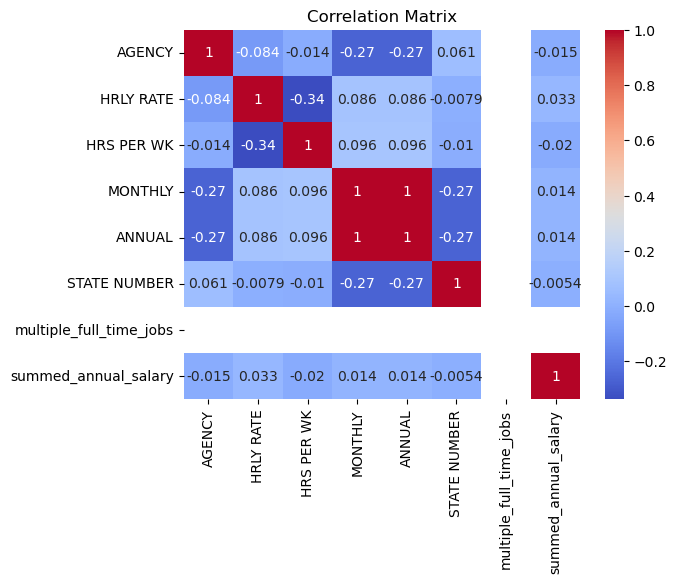

In [97]:
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

### Top Agencies by Average Salary

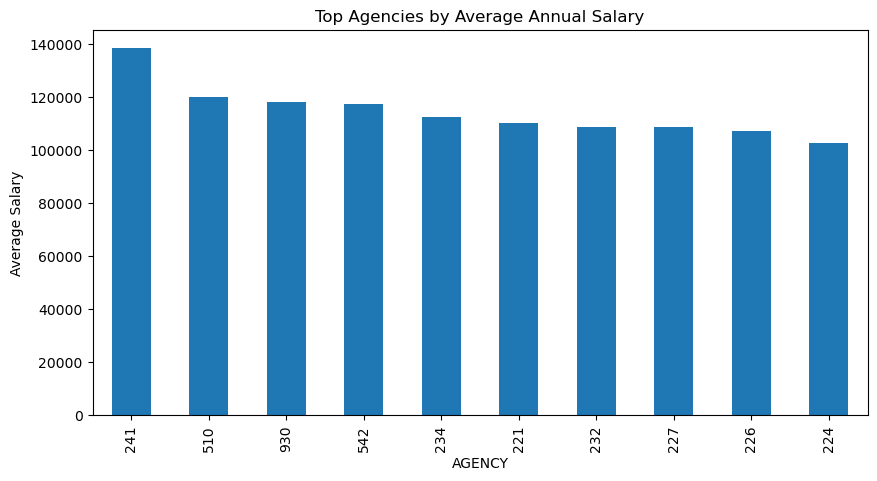

In [102]:
top_agencies = df.groupby('AGENCY')['ANNUAL'].mean().sort_values(ascending=False).head(10)
top_agencies.plot(kind='bar', figsize=(10,5), title='Top Agencies by Average Annual Salary')
plt.ylabel('Average Salary')
plt.show()

### Gender-wise Salary Distribution by Role

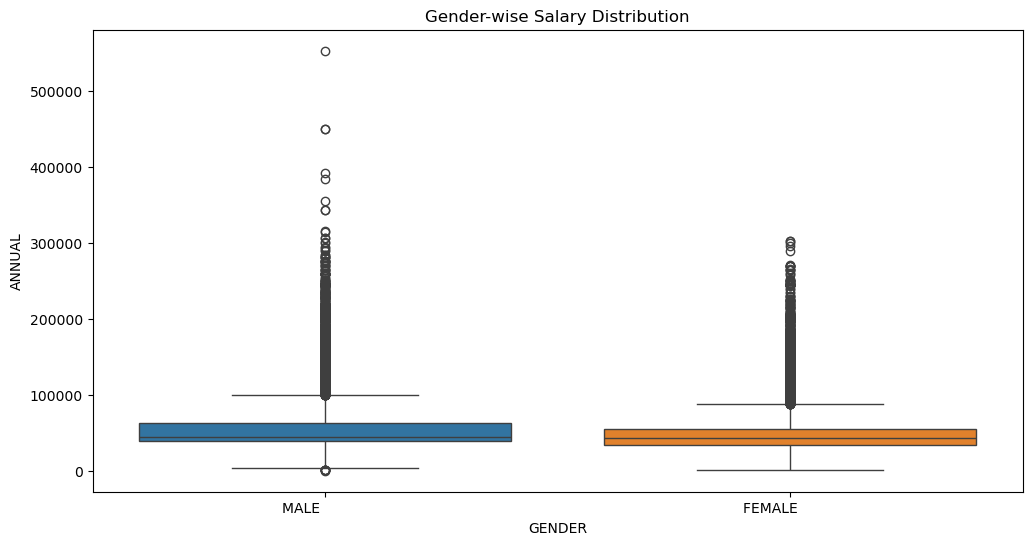

In [105]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='GENDER', y='ANNUAL', hue='GENDER', data=df)
plt.title('Gender-wise Salary Distribution')
plt.show()

### Top Earning Roles

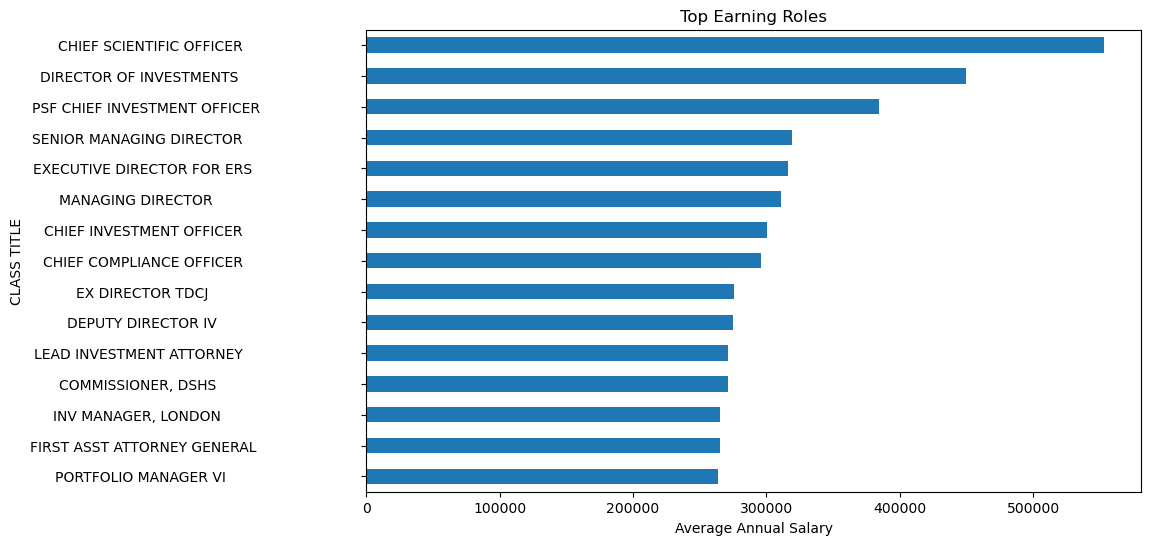

In [110]:
top_roles = df.groupby('CLASS TITLE')['ANNUAL'].mean().sort_values(ascending=False).head(15)
top_roles.plot(kind='barh', figsize=(10,6), title='Top Earning Roles')
plt.xlabel('Average Annual Salary')
plt.gca().invert_yaxis()
plt.show()

### Gender Distribution

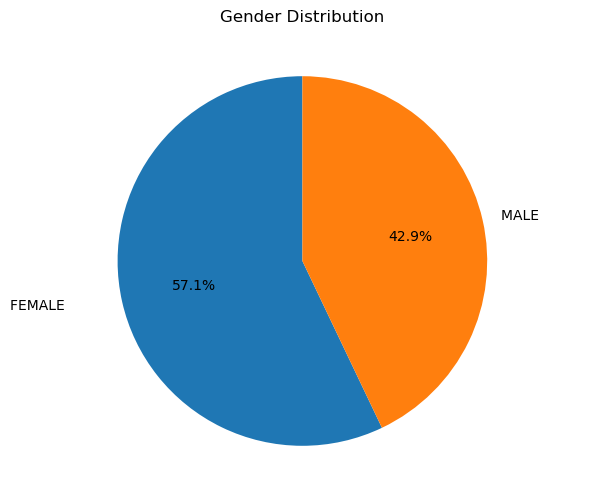

In [113]:
gender_counts = df['GENDER'].value_counts()
gender_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, title='Gender Distribution', figsize=(6, 6))
plt.ylabel('')
plt.show()

### Ethnicity Distribution

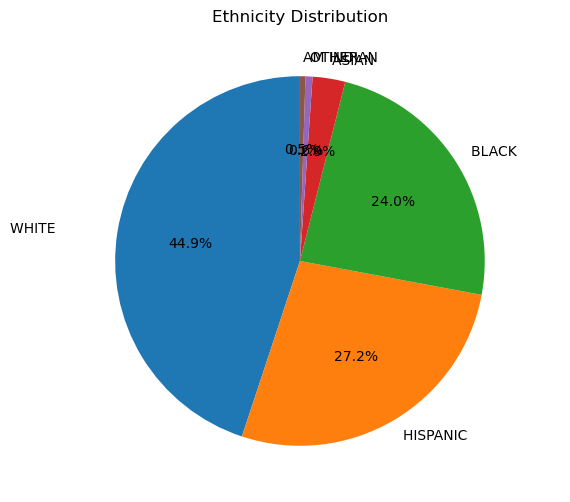

In [116]:
ethnicity_counts = df['ETHNICITY'].value_counts()
ethnicity_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90, title='Ethnicity Distribution', figsize=(6, 6))
plt.ylabel('')
plt.show()

## Challenges and Observations

- Missing and inconsistent data
- Outliers in salaries skewing results
- High cardinality in categorical features (many unique job titles)
- Imbalance in roles and demographics

### Final Recommendation:
Use **Random Forest** or **XGBoost** due to higher R2 scores and robustness to outliers.


## 📋 Final Data Analysis Report

### Insights:
- The salary distribution is **right-skewed**, with a small number of employees earning extremely high salaries.
- **Outliers** are present and were identified using the IQR method.
- **Gender** and **Ethnicity** disparities are noticeable — males and some ethnic groups dominate higher salary brackets.
- Some **job titles** show significantly higher average salaries (e.g., executive or director-level roles).
- Over time, average salaries have shown an **increasing trend**, especially in more recent years.

### Modeling:
- Three models were built: **Linear Regression**, **Random Forest**, and **XGBoost**.
- Based on **R² score** and **MSE**, **XGBoost** performed the best, closely followed by Random Forest.
- **Feature encoding** using `pd.get_dummies` was effective in preparing categorical data.

### Challenges Faced:
- High cardinality in job titles and agencies.
- Missing values in several columns (addressed using median/mode).
- Unbalanced data distributions in roles and salaries.
- Inconsistent date formats handled during preprocessing.

### Final Recommendation:
- Deploy **XGBoost model** for salary prediction due to its robustness and performance.
- Further improvements can be made with better feature engineering (e.g., job hierarchy encoding, agency clustering).
